# Linear-chain hybrid surgery

`surgery_hybrid_linear` step by step: SED → clusterise the merge region → (loop) → split into linear resource states → cut time edges → hybrid realisation → experiment → circuit, for each decomposition.

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt

from dizx.builders import BUILDERS, surgery_layers
from dizx.circuit_extractor import to_stim
from dizx.dem_view import plot_dem
from dizx.realisation import QECExperiment, RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery
from walkthrough import erasure, erasure_sweep, full_and_seam, plot_sweep
import numpy as np

from dizx.realisation import resource_states
from dizx.transformations import loop_boundary, prepare_cluster_region
from walkthrough import draw_resource_states

In [2]:
# builder suffix: (period k, looped)
VARIANTS = {"3dchain": (None, False), "5chain": (1, False), "8chain": (2, False), "looped": (None, True)}
PS = {"3dchain": [0.4, 0.45, 0.5, 0.55, 0.6], "5chain": [0.2, 0.25, 0.3, 0.35, 0.4],
      "8chain": [0.3, 0.35, 0.4, 0.45, 0.5], "looped": [0.4, 0.45, 0.5, 0.55, 0.6]}

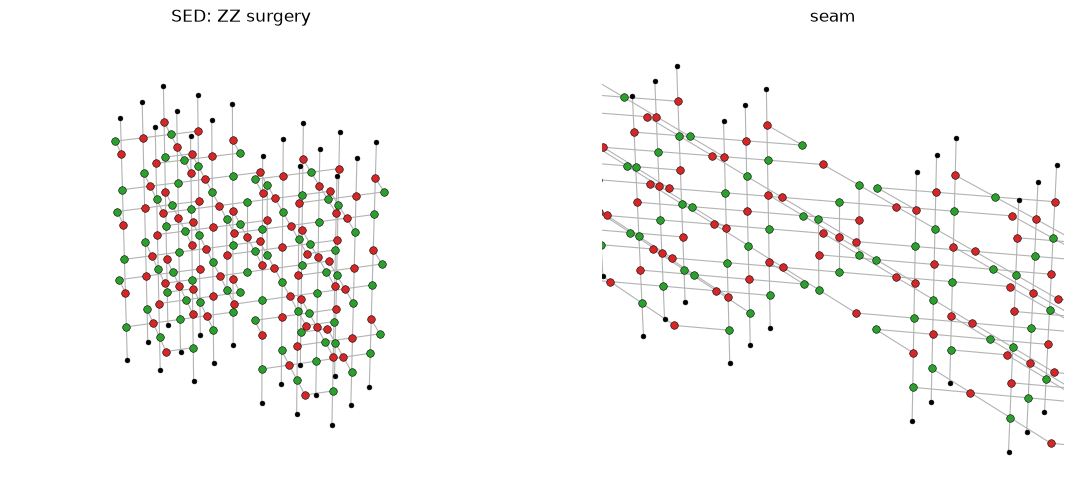

In [3]:
d, n = 3, 1
s = two_patch_surgery(d, "ZZ", layers=surgery_layers(n))
full_and_seam(s.sed, d, "SED: ZZ surgery")

## Clusterise the merge region

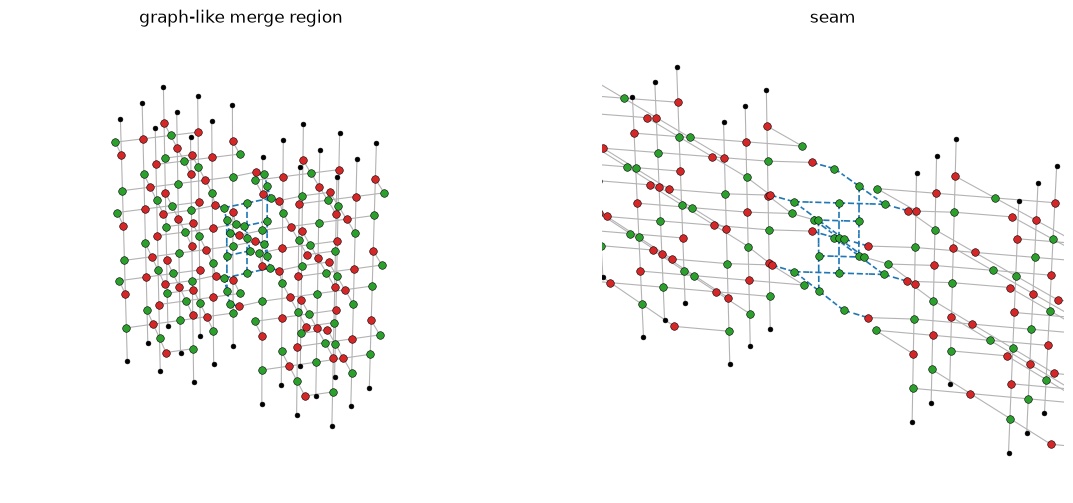

In [4]:
cl, S = prepare_cluster_region(s.sed, s.merge_region())
full_and_seam(cl, d, "graph-like merge region")

## Split into linear chains (3d-chain)

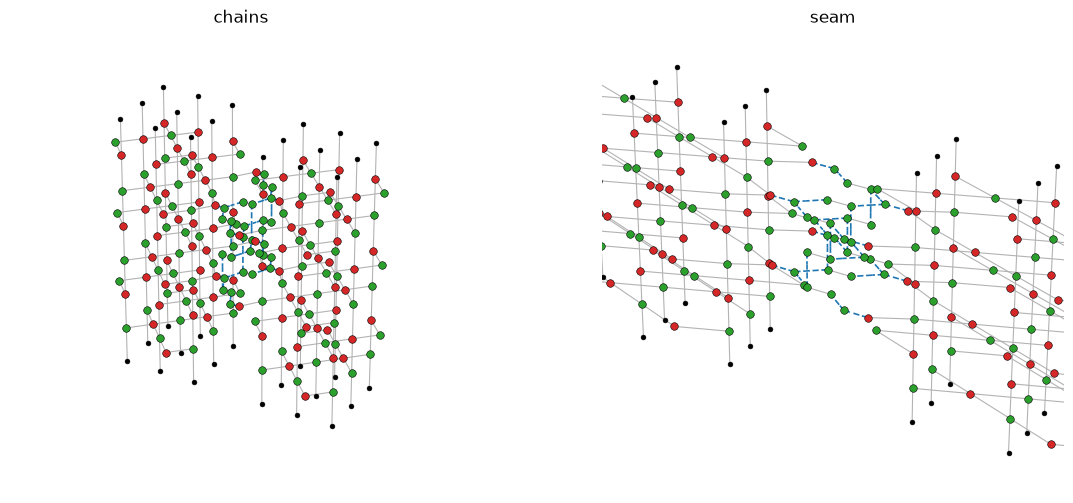

In [5]:
chains, fusions = s.split_seam_linear(cl)
full_and_seam(chains, d, "chains")

## Cut time edges every k-th step (k=1: 5-chain)

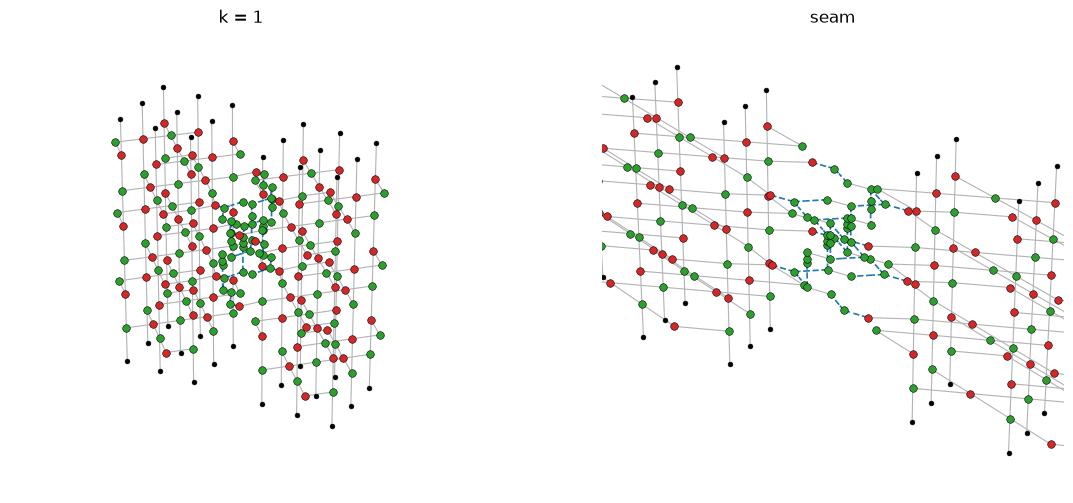

In [6]:
cut, cuts = s.cut_time_edges(chains, S | {v for e in fusions for v in e}, period=1)
full_and_seam(cut, d, "k = 1")

## Loop the region boundary (looped)

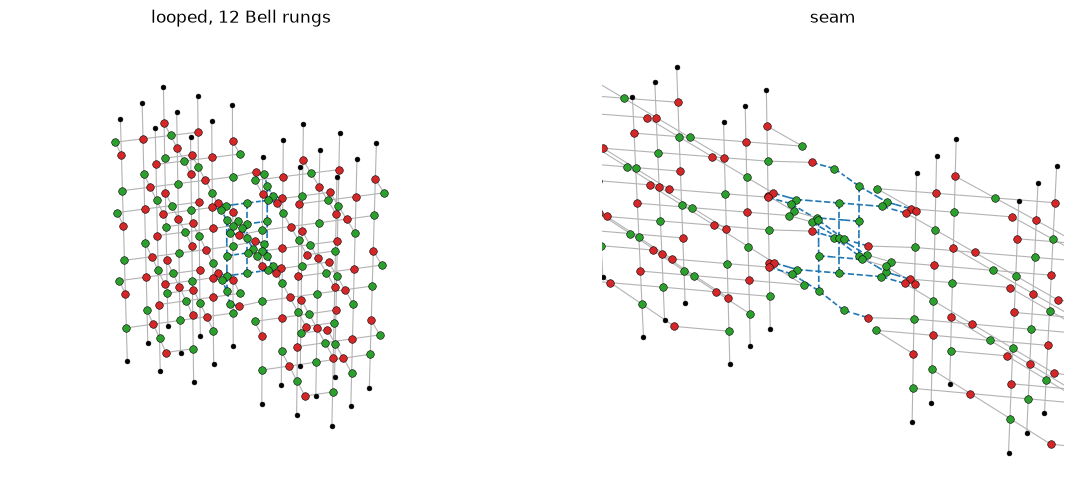

In [7]:
looped, S_l, rungs = loop_boundary(cl, S)
full_and_seam(looped, d, f"looped, {len(rungs)} Bell rungs")

## Realisations

Each is `surgery_hybrid_linear(..., period=k, looped=...)`. Colours: resource states; black: fusions; dashed: Bell pairs.

3dchain  states [2, 2, 3, 3, 9, 9]  fusions 19  bell 0
5chain   states [2, 2, 2, 2, 3, 3, 3, 3, 5, 5, 5, 5]  fusions 25  bell 0


8chain   states [2, 2, 2, 3, 3, 3, 5, 6, 8]  fusions 22  bell 0
looped   states [2, 2, 2, 2, 3, 3, 3, 4, 4, 4, 4]  fusions 24  bell 12


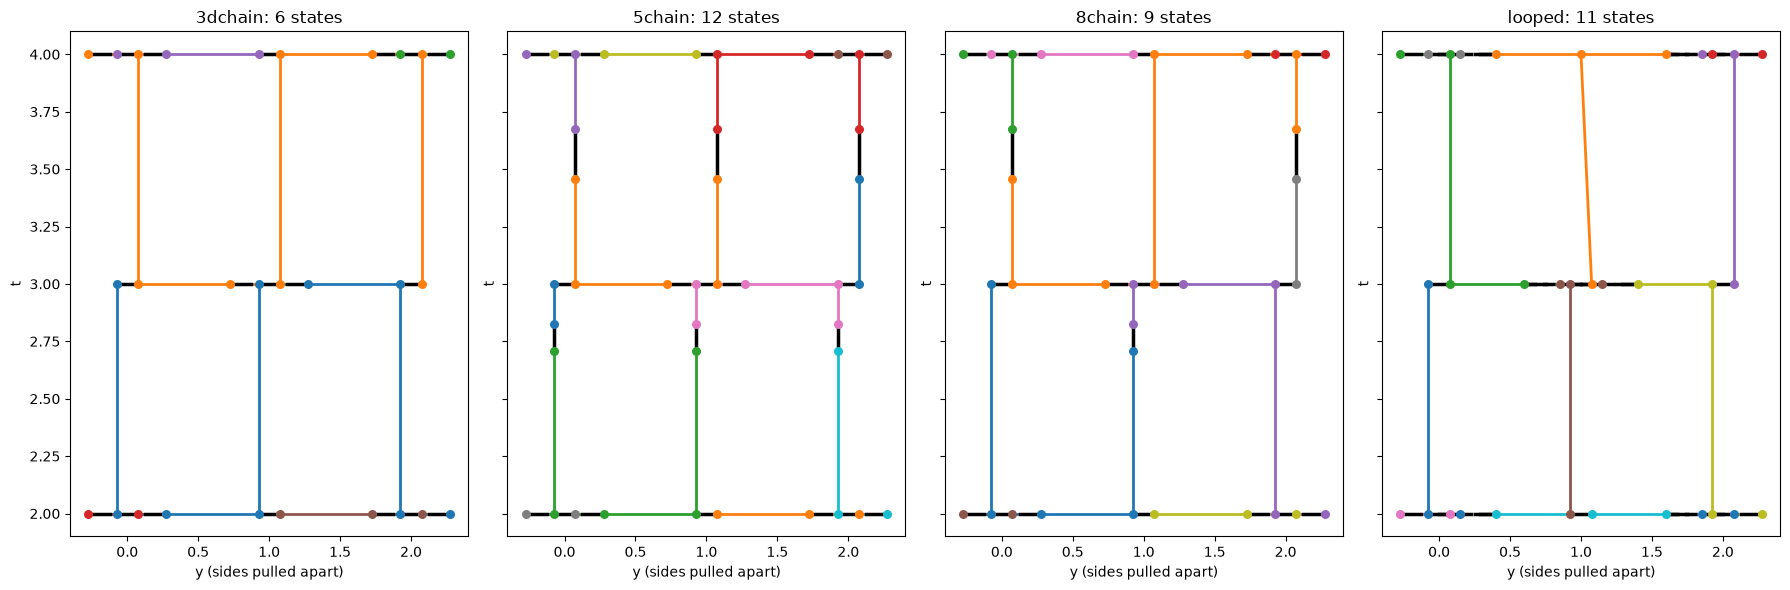

In [8]:
def experiment(real, observable):
    """Patches prepared in X (ZZ merge), measured in the observable's basis."""
    return QECExperiment(real, {p: "X" for p in real.inputs},
                         {p: observable[0] for p in real.outputs})


from dizx.surgery import surgery_hybrid_linear

fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
for i, (name, (k, lp)) in enumerate(VARIANTS.items()):
    s_, real, S_ = surgery_hybrid_linear(d, "ZZ", layers=surgery_layers(n), period=k, looped=lp)
    circuit = to_stim(experiment(real, "ZZ"), RotatedSurfaceCodeSchedule(s_.merged), fusions="gates")
    assert circuit == BUILDERS[f"surgery_hybrid_linear_{name}"](distance=d, n_cycles=n).circuit
    sizes = sorted(len(c) for c in resource_states(real, S_))
    kinds = [l.kind for l in real.links]
    print(f"{name:8} states {sizes}  fusions {kinds.count('fusion')}  bell {kinds.count('bell')}")
    draw_resource_states(real, S_, d, ax=axes[i], title=f"{name}: {len(sizes)} states")
fig.tight_layout()

## Experiment (5-chain)

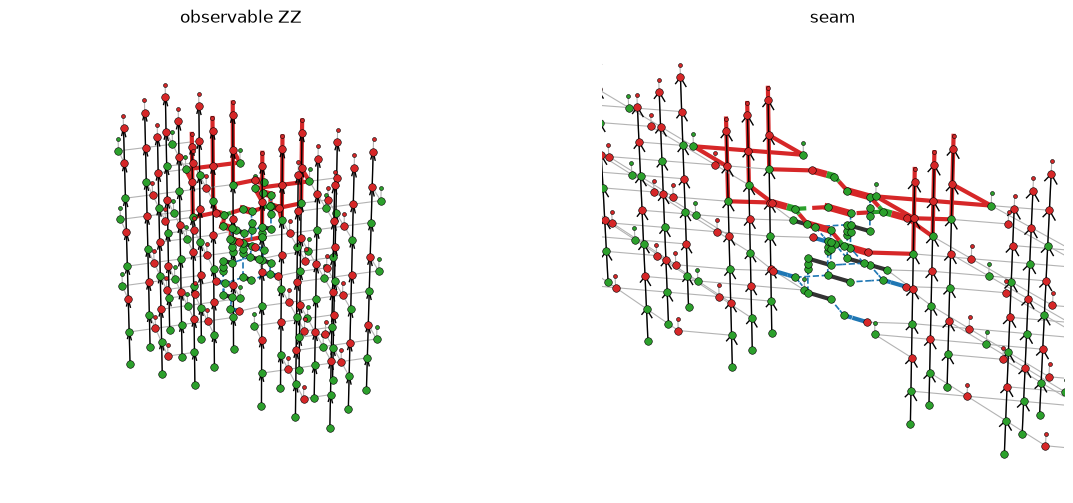

In [9]:
_, real, _ = surgery_hybrid_linear(d, "ZZ", layers=surgery_layers(n), period=1)
exp = experiment(real, "ZZ")
full_and_seam(exp, d, "observable ZZ", web=exp.observables[0])

## Interface DEMs (fusion erasure)

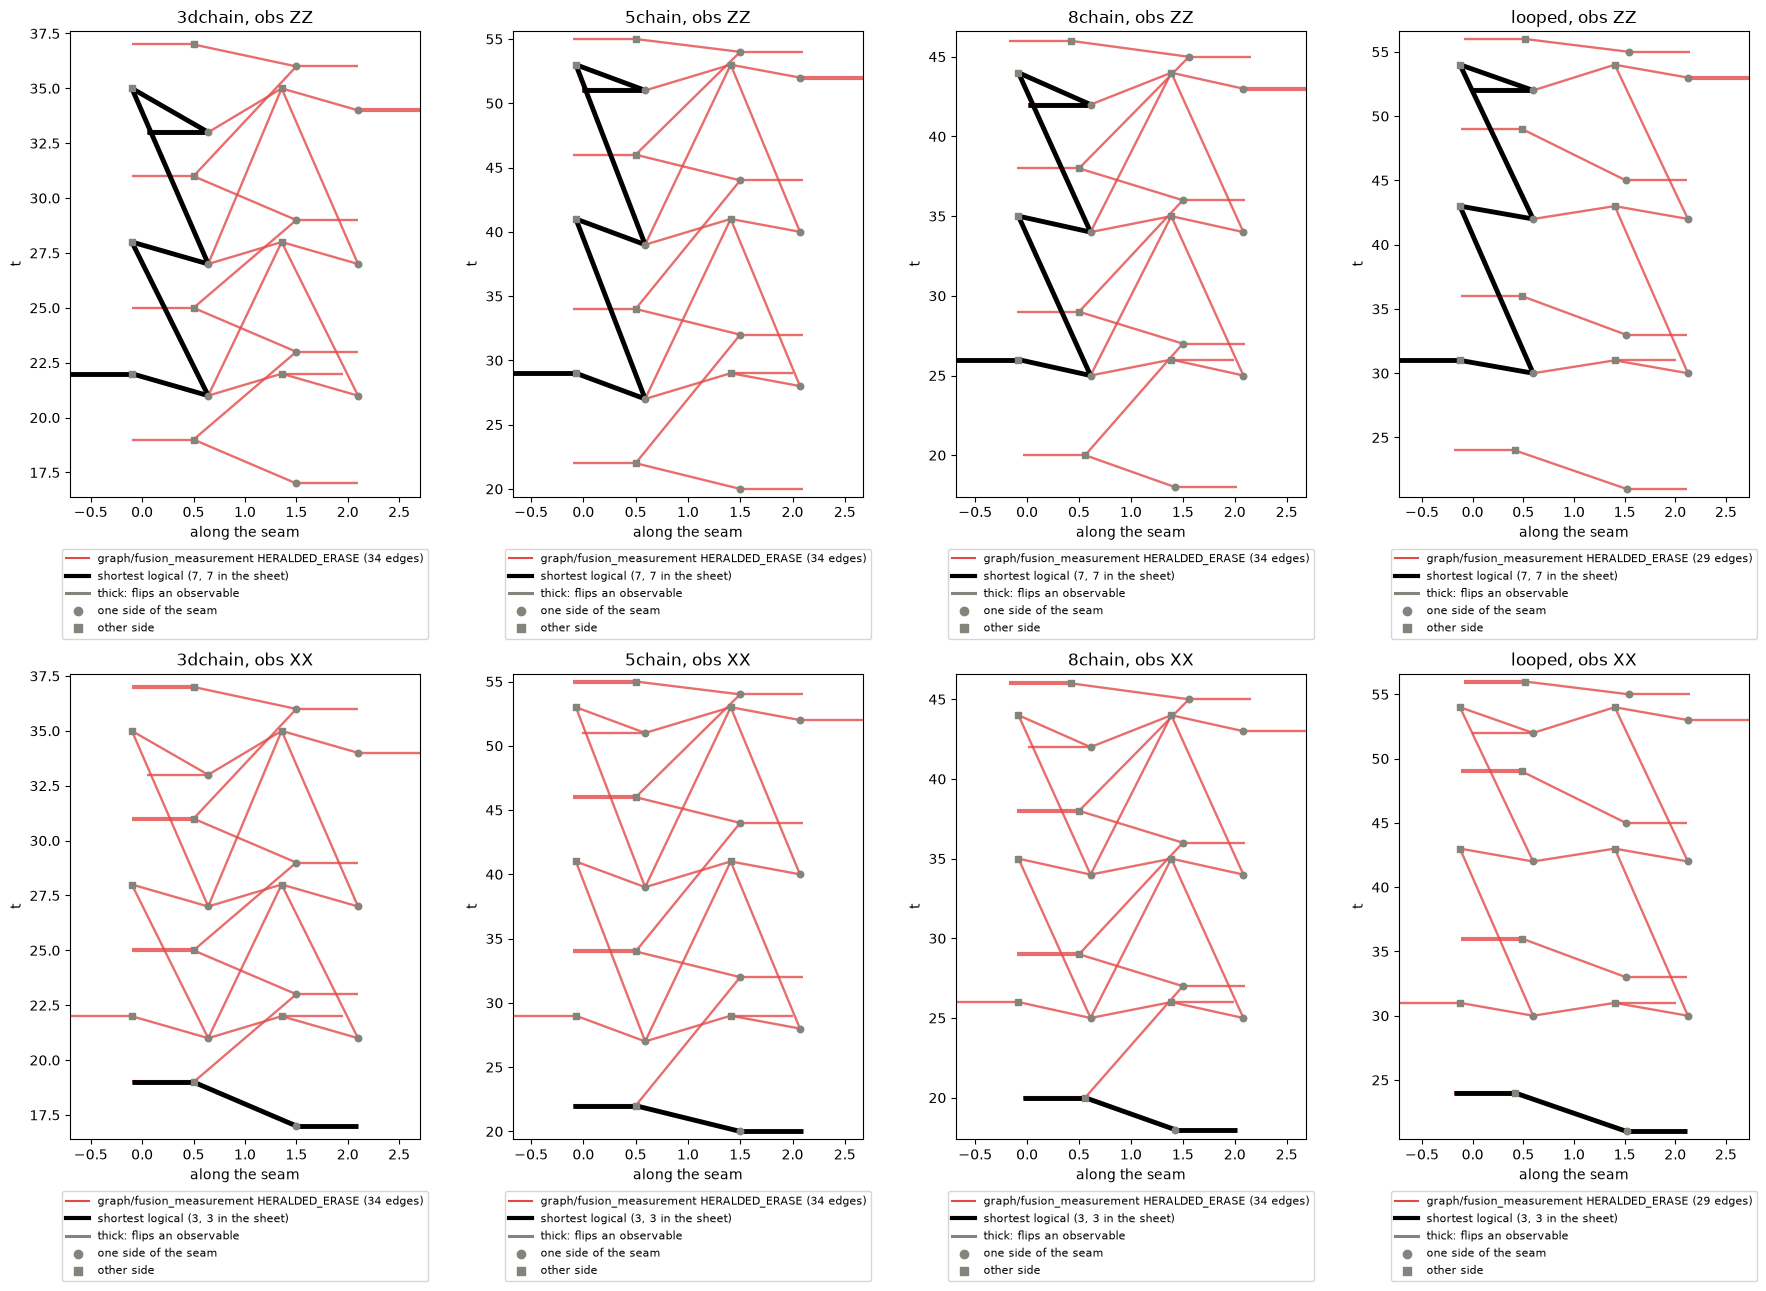

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 13))
for row, obs in zip(axes, ("ZZ", "XX")):
    for ax, name in zip(row, VARIANTS):
        c = BUILDERS[f"surgery_hybrid_linear_{name}"](distance=3, n_cycles=3, observable=obs).circuit
        plot_dem(c, erasure(("graph", "fusion_measurement"), 0.1), ax=ax, sheet=True, title=f"{name}, obs {obs}")
fig.tight_layout()

## Pure erasure sweeps

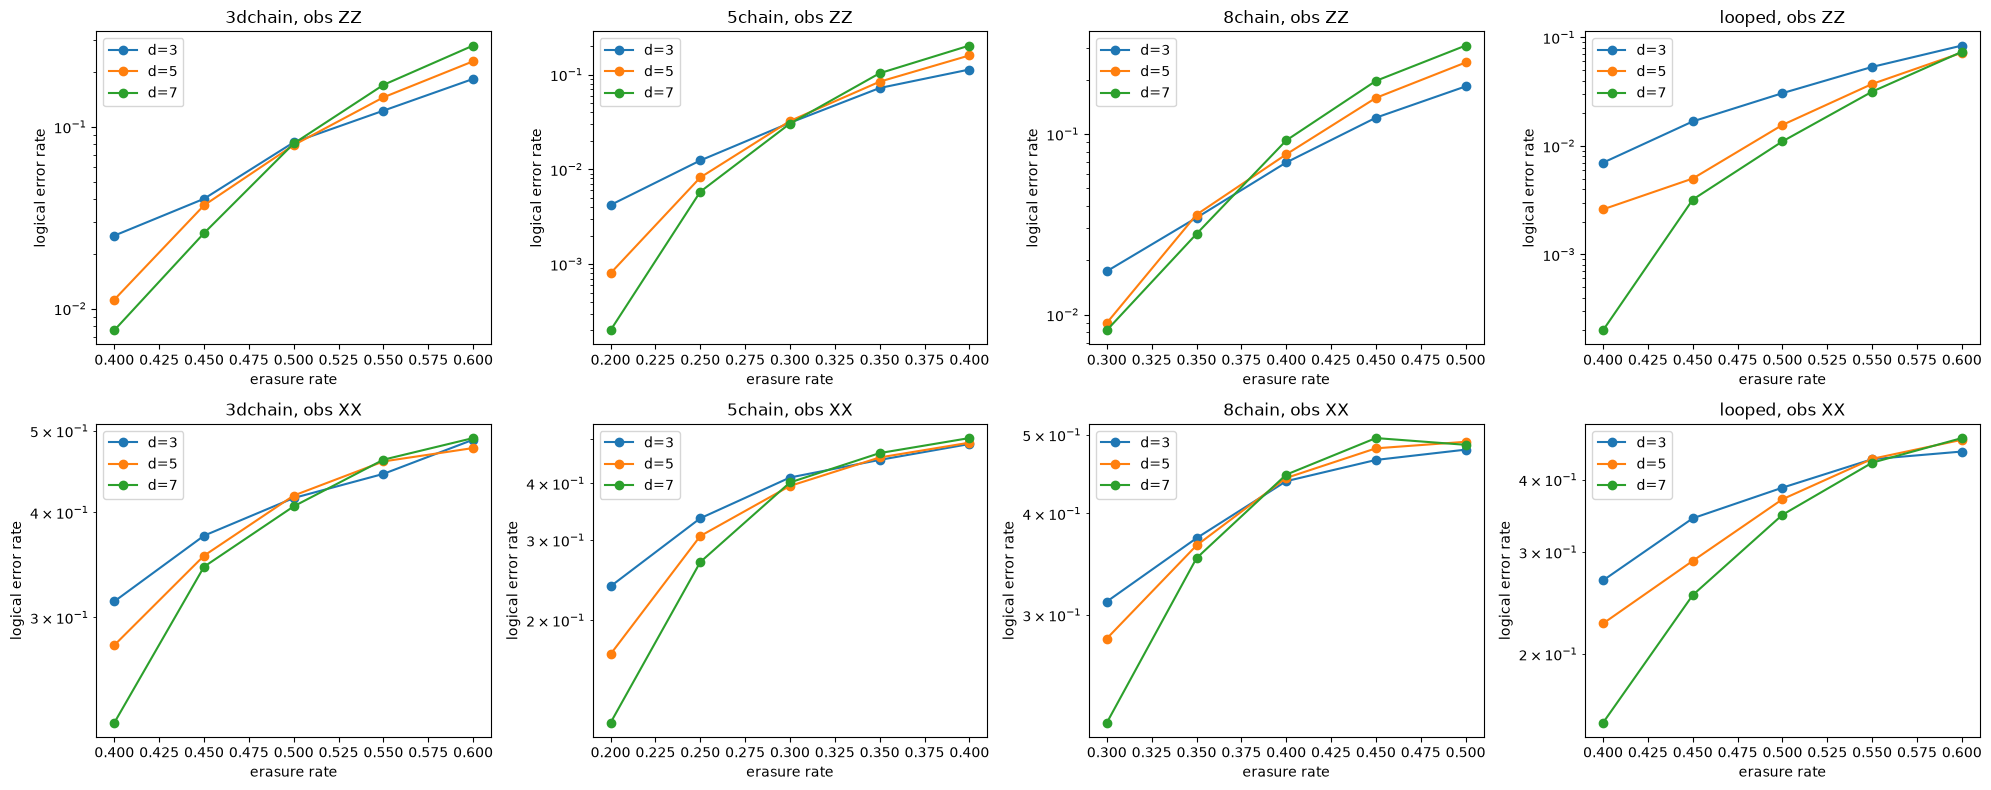

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for row, obs in zip(axes, ("ZZ", "XX")):
    for ax, name in zip(row, VARIANTS):
        b = BUILDERS[f"surgery_hybrid_linear_{name}"]
        rates = erasure_sweep(lambda d: b(distance=d, n_cycles=d, observable=obs).circuit, ("graph", "fusion_measurement"),
                              [3, 5, 7], PS[name], shots=5_000)
        plot_sweep(rates, PS[name], ax=ax, title=f"{name}, obs {obs}")
fig.tight_layout()